El método de **Newton-Raphson** permite aproximar una raíz de una función a partir de una estimación inicial. Este ejemplo combina una explicación matemática, una implementación en Python y una visualización de las iteraciones.

## La idea

Para encontrar un valor de $x$ tal que $f(x)=0$, partimos de un valor $x_i$ y calculamos una nueva aproximación mediante

$$
x_{i+1}=x_i-\frac{f(x_i)}{f'(x_i)}.
$$

Esta expresión puede interpretarse geométricamente mediante la recta tangente a la curva en $x_i$. El proceso se repite hasta alcanzar una tolerancia determinada.

## Ejemplo: $f(x)=x^3-x-2$

Consideremos $f(x)=x^3-x-2$, cuya derivada es $f'(x)=3x^2-1$. Utilizaremos $x_0=1$ como estimación inicial.

In [1]:
def f(x):
    return x**3 - x - 2


def df(x):
    return 3*x**2 - 1


def newton_raphson(x0, tol=1e-10, max_iter=20):
    history = [x0]
    x = x0
    for _ in range(max_iter):
        derivative = df(x)
        if abs(derivative) < 1e-12:
            raise ValueError("Derivada demasiado cercana a cero")
        x_next = x - f(x) / derivative
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return history

In [2]:
history = newton_raphson(1.0)
for i, x in enumerate(history):
    print(f"i={i}: x={x:.10f}, f(x)={f(x):+.3e}")

i=0: x=1.0000000000, f(x)=-2.000e+0
i=1: x=2.0000000000, f(x)=+4.000e+0
i=2: x=1.6363636364, f(x)=+7.453e-1
i=3: x=1.5303920521, f(x)=+5.394e-2
i=4: x=1.5214414651, f(x)=+3.671e-4
i=5: x=1.5213797097, f(x)=+1.741e-8
i=6: x=1.5213797068, f(x)=+0.000e+0
i=7: x=1.5213797068, f(x)=+0.000e+0


La secuencia se aproxima a una raíz cercana a $1.52138$. Con Matplotlib podemos observar la función y las primeras aproximaciones.

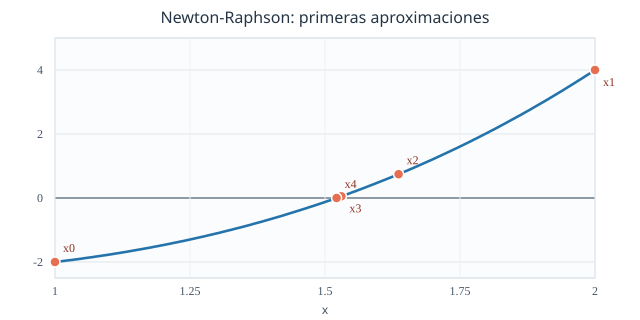

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats

set_matplotlib_formats("svg")
plt.rcParams["svg.fonttype"] = "none"

xs = np.linspace(1.0, 2.0, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(xs, f(xs), label=r"$f(x)=x^3-x-2$")
ax.axhline(0, color="gray", linewidth=0.9)
ax.scatter(history[:5], [f(x) for x in history[:5]],
           zorder=3, label="Aproximaciones")
ax.set(xlabel="x", ylabel="f(x)", title="Newton-Raphson: iteraciones iniciales")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

## Observación

En este caso, el método converge rápidamente. Sin embargo, **la convergencia no está garantizada**: depende de la función y de la estimación inicial. En particular, una derivada nula o demasiado pequeña puede producir problemas numéricos.

Este artículo se ha escrito como un notebook de Jupyter y convertido a Markdown para publicarlo con Jekyll.

## Probando algunas cosas más 

In [1]:
from moro import Robot, enable_vprinting
from moro.abc import q1,q2
enable_vprinting()

In [2]:
RR = Robot((100,0,0,q1), (100,0,0,q2))

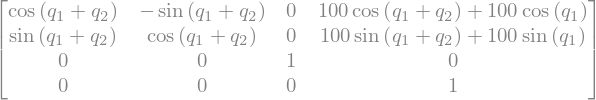

In [12]:
RR.T

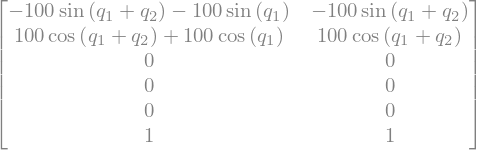

In [14]:
RR.J

In [20]:
RR.model_summary()

'Model summary | Robot RR | DOF = 2\n  joint_limits     : default\n  masses           : NOT SET\n  inertia_tensors  : NOT SET\n  cm_positions     : NOT SET\n  gravity          : NOT SET'

In [22]:
RR.q_dot(1)

In [24]:
RR.q(1)

In [26]:
from moro.visualization import RobotVisualizer

In [28]:
viz = RobotVisualizer(RR)

(<Figure size 1000x800 with 1 Axes>,
 <Axes3D: xlabel='X', ylabel='Y', zlabel='Z'>)

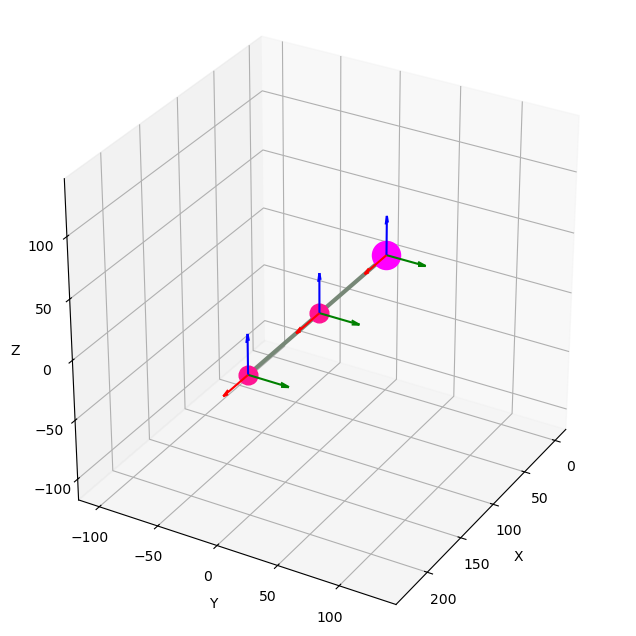

In [32]:
viz.plot(
    [0,0],
    backend="matplotlib"
)

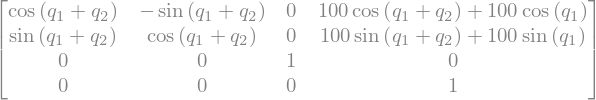

In [3]:
RR.T

$$
a^2 + b^2
$$